# COMSATS University Islamabad
## Artificial Neural Networks & Deep Learning — Lab Assignment 2

**Student Name:** ABDUL MOIZ ABBASI

**Registration Number:** FA23-BAI-001


## Cell 1 — Import libraries and set reproducibility

In [1]:
import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("NumPy:", np.__version__)
print("Setup complete.")


NumPy: 2.1.3
Setup complete.


# Task 1 — Multilayer Perceptron (MLP) on Iris

We compare weight initialization, learning-rate strategies, batch sizes, regularization, and early stopping. The test set is held out until final evaluation. Data preprocessing is fitted on training data only.


## Cell 2 — Load Iris and split into training, validation, and test sets

In [2]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder

iris = load_iris()
X = iris.data.astype(np.float32)
y = iris.target

X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.25,
    stratify=y_trainval, random_state=SEED
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train).astype(np.float32)
X_val = scaler.transform(X_val).astype(np.float32)
X_test = scaler.transform(X_test).astype(np.float32)

try:
    encoder = OneHotEncoder(sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(sparse=False)

y_train_oh = encoder.fit_transform(y_train.reshape(-1, 1)).astype(np.float32)
y_val_oh = encoder.transform(y_val.reshape(-1, 1)).astype(np.float32)
y_test_oh = encoder.transform(y_test.reshape(-1, 1)).astype(np.float32)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)
print("Classes:", iris.target_names)


Training: (90, 4)
Validation: (30, 4)
Testing: (30, 4)
Classes: ['setosa' 'versicolor' 'virginica']


## Cell 3 — Define the MLP model builder

In [3]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

tf.random.set_seed(SEED)

def build_mlp(initializer="he", learning_rate=0.01,
              lr_schedule=False, l2_strength=0.0, dropout=0.0):
    if initializer.lower() == "he":
        init = keras.initializers.HeNormal(seed=SEED)
    elif initializer.lower() == "glorot":
        init = keras.initializers.GlorotUniform(seed=SEED)
    else:
        raise ValueError("initializer must be 'he' or 'glorot'")

    reg = regularizers.l2(l2_strength) if l2_strength > 0 else None

    model = keras.Sequential([
        layers.Input(shape=(4,)),
        layers.Dense(32, activation="relu",
                     kernel_initializer=init, kernel_regularizer=reg),
        layers.Dropout(dropout) if dropout > 0 else layers.Activation("linear"),
        layers.Dense(16, activation="relu",
                     kernel_initializer=init, kernel_regularizer=reg),
        layers.Dense(3, activation="softmax")
    ])

    if lr_schedule:
        lr = keras.optimizers.schedules.ExponentialDecay(
            initial_learning_rate=learning_rate,
            decay_steps=50,
            decay_rate=0.90,
            staircase=False
        )
    else:
        lr = learning_rate

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

print("Model builder defined.")


Model builder defined.


## Cell 4 — Compare He and Glorot initialization

,Initialization,Validation Loss,Validation Accuracy
0,he,0.500238,0.933333
1,glorot,0.381551,0.933333


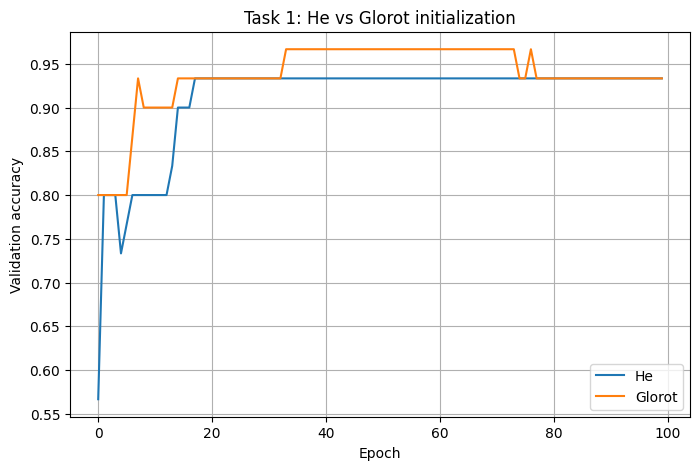

In [4]:
init_results = []
init_histories = {}

for init_name in ["he", "glorot"]:
    tf.keras.backend.clear_session()
    model = build_mlp(initializer=init_name, learning_rate=0.01)
    history = model.fit(
        X_train, y_train_oh,
        validation_data=(X_val, y_val_oh),
        epochs=100, batch_size=16, verbose=0
    )
    loss, acc = model.evaluate(X_val, y_val_oh, verbose=0)
    init_results.append({
        "Initialization": init_name,
        "Validation Loss": loss,
        "Validation Accuracy": acc
    })
    init_histories[init_name] = history.history

display(pd.DataFrame(init_results))

plt.figure(figsize=(8, 5))
for name, hist in init_histories.items():
    plt.plot(hist["val_accuracy"], label=name.capitalize())
plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.title("Task 1: He vs Glorot initialization")
plt.legend()
plt.grid(True)
plt.show()


## Cell 5 — Compare constant and scheduled learning rates

,Learning rate,Validation Loss,Validation Accuracy
0,Constant LR,0.483906,0.933333
1,Exponential schedule,0.503084,0.933333


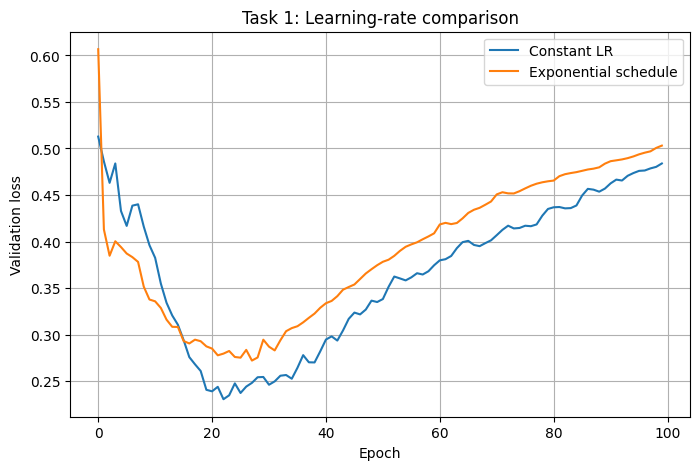

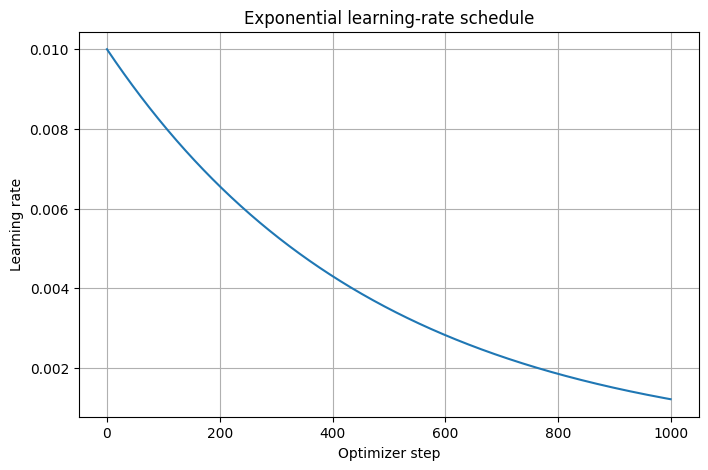

In [5]:
lr_results = []
lr_histories = {}

for scheduled in [False, True]:
    tf.keras.backend.clear_session()
    model = build_mlp(
        initializer="he", learning_rate=0.01, lr_schedule=scheduled
    )
    history = model.fit(
        X_train, y_train_oh,
        validation_data=(X_val, y_val_oh),
        epochs=100, batch_size=16, verbose=0
    )
    loss, acc = model.evaluate(X_val, y_val_oh, verbose=0)
    name = "Exponential schedule" if scheduled else "Constant LR"
    lr_results.append({
        "Learning rate": name,
        "Validation Loss": loss,
        "Validation Accuracy": acc
    })
    lr_histories[name] = history.history

display(pd.DataFrame(lr_results))

plt.figure(figsize=(8, 5))
for name, hist in lr_histories.items():
    plt.plot(hist["val_loss"], label=name)
plt.xlabel("Epoch")
plt.ylabel("Validation loss")
plt.title("Task 1: Learning-rate comparison")
plt.legend()
plt.grid(True)
plt.show()

schedule = keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate=0.01, decay_steps=50, decay_rate=0.90
)
steps = np.arange(0, 1000)
plt.figure(figsize=(8, 5))
plt.plot(steps, schedule(steps).numpy())
plt.xlabel("Optimizer step")
plt.ylabel("Learning rate")
plt.title("Exponential learning-rate schedule")
plt.grid(True)
plt.show()


## Cell 6 — Compare batch sizes and epoch limits

In [6]:
batch_results = []

for batch_size in [8, 16, 32]:
    for epochs in [50, 100]:
        tf.keras.backend.clear_session()
        model = build_mlp(initializer="he", learning_rate=0.01)
        history = model.fit(
            X_train, y_train_oh,
            validation_data=(X_val, y_val_oh),
            epochs=epochs, batch_size=batch_size, verbose=0
        )
        loss, acc = model.evaluate(X_val, y_val_oh, verbose=0)
        batch_results.append({
            "Batch size": batch_size,
            "Epoch limit": epochs,
            "Epochs completed": len(history.history["loss"]),
            "Validation loss": loss,
            "Validation accuracy": acc
        })

display(pd.DataFrame(batch_results).sort_values(
    ["Validation accuracy", "Validation loss"],
    ascending=[False, True]
).reset_index(drop=True))


,Batch size,Epoch limit,Epochs completed,Validation loss,Validation accuracy
0,32,100,100,0.304514,0.933333
1,8,50,50,0.335009,0.933333
2,16,50,50,0.335289,0.933333
3,16,100,100,0.428274,0.933333
4,32,50,50,0.396904,0.900000
5,8,100,100,0.513935,0.900000


## Cell 7 — Compare baseline, L2 regularization, and dropout

,Model,Validation loss,Validation accuracy
0,Baseline,0.750218,0.900000
1,L2 regularization,0.254652,0.933333
2,Dropout,0.528043,0.933333


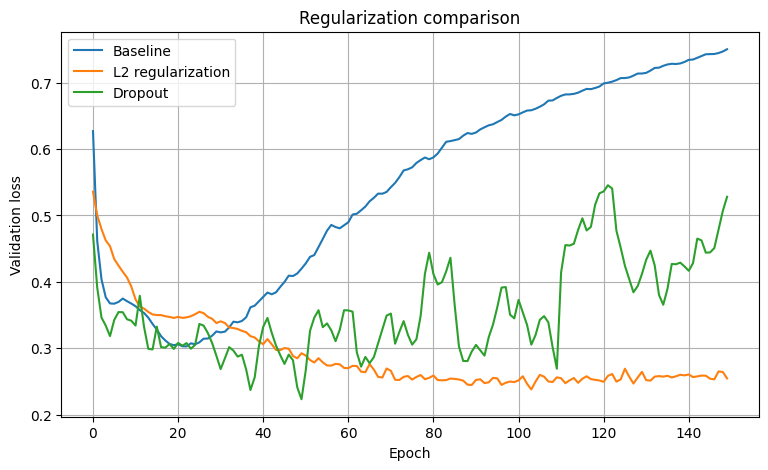

In [7]:
reg_results = []
reg_histories = {}

configs = [
    ("Baseline", 0.0, 0.0),
    ("L2 regularization", 0.001, 0.0),
    ("Dropout", 0.0, 0.30)
]

for name, l2_value, dropout_value in configs:
    tf.keras.backend.clear_session()
    model = build_mlp(
        initializer="he",
        learning_rate=0.01,
        l2_strength=l2_value,
        dropout=dropout_value
    )
    history = model.fit(
        X_train, y_train_oh,
        validation_data=(X_val, y_val_oh),
        epochs=150, batch_size=16, verbose=0
    )
    loss, acc = model.evaluate(X_val, y_val_oh, verbose=0)
    reg_results.append({
        "Model": name,
        "Validation loss": loss,
        "Validation accuracy": acc
    })
    reg_histories[name] = history.history

display(pd.DataFrame(reg_results))

plt.figure(figsize=(9, 5))
for name, hist in reg_histories.items():
    plt.plot(hist["val_loss"], label=name)
plt.xlabel("Epoch")
plt.ylabel("Validation loss")
plt.title("Regularization comparison")
plt.legend()
plt.grid(True)
plt.show()


## Cell 8 — Early stopping and learning curves

Epochs run: 45
Best validation loss: 0.22752776741981506


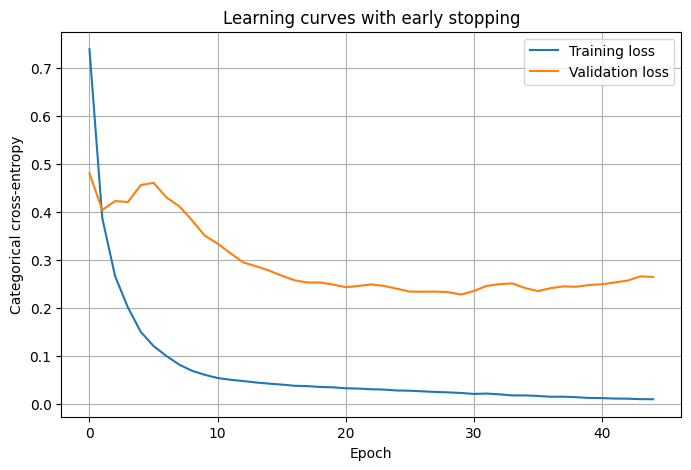

In [8]:
tf.keras.backend.clear_session()

early_model = build_mlp(initializer="he", learning_rate=0.01)
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

early_history = early_model.fit(
    X_train, y_train_oh,
    validation_data=(X_val, y_val_oh),
    epochs=300,
    batch_size=16,
    callbacks=[early_stop],
    verbose=0
)

print("Epochs run:", len(early_history.history["loss"]))
print("Best validation loss:", min(early_history.history["val_loss"]))

plt.figure(figsize=(8, 5))
plt.plot(early_history.history["loss"], label="Training loss")
plt.plot(early_history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Categorical cross-entropy")
plt.title("Learning curves with early stopping")
plt.legend()
plt.grid(True)
plt.show()


## Cell 9 — Final test-set evaluation

Test loss: 0.2525
Test accuracy: 0.9000

Classification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.89      0.80      0.84        10
   virginica       0.82      0.90      0.86        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



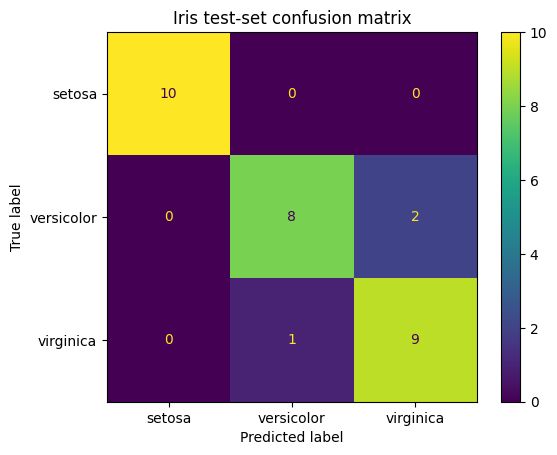

In [9]:
test_loss, test_accuracy = early_model.evaluate(
    X_test, y_test_oh, verbose=0
)
probabilities = early_model.predict(X_test, verbose=0)
y_pred = np.argmax(probabilities, axis=1)

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print("\nClassification report:")
print(classification_report(
    y_test, y_pred, target_names=iris.target_names, zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=iris.target_names
)
plt.title("Iris test-set confusion matrix")
plt.show()


### Task 1 — Discussion

Use the generated results to discuss:
- Which initialization achieved better validation performance?
- Did the learning-rate schedule improve convergence?
- How did batch size and epoch limit affect results?
- Did L2 or dropout reduce overfitting?
- At which epoch did early stopping finish?
- Report the final test loss, accuracy, and classification metrics.

The best configuration is not guaranteed to be identical on every run. The test set is used only for final evaluation.


# Task 2A — Adaline for the bipolar AND gate

Adaline uses a linear net input and the LMS/delta learning rule. The sign function converts the net input into a bipolar class prediction.


## Cell 10 — Train Adaline on bipolar AND

Final weights: [0.52941143 0.55882347]
Final bias: -0.4999995207989611

Input | Target | Net input | Prediction
[-1. -1.] |     -1 |   -1.5882 |         -1
[-1.  1.] |     -1 |   -0.4706 |         -1
[ 1. -1.] |     -1 |   -0.5294 |         -1
[1. 1.] |      1 |    0.5882 |          1

MSE: 0.25432523295444803


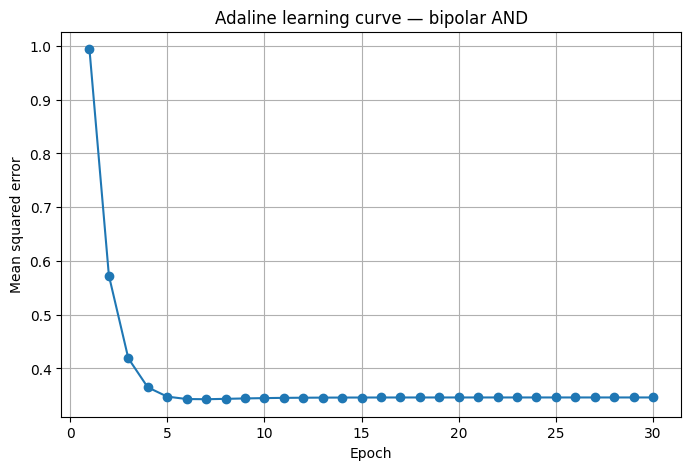

In [10]:
X_and = np.array([
    [-1, -1],
    [-1,  1],
    [ 1, -1],
    [ 1,  1]
], dtype=float)

y_and = np.array([-1, -1, -1, 1], dtype=float)

weights = np.zeros(2, dtype=float)
bias = 0.0
learning_rate = 0.1
epochs = 30
mse_history = []

for epoch in range(epochs):
    squared_errors = []
    for xi, target in zip(X_and, y_and):
        net = np.dot(xi, weights) + bias
        error = target - net
        weights += learning_rate * error * xi
        bias += learning_rate * error
        squared_errors.append(error ** 2)
    mse_history.append(np.mean(squared_errors))

net_outputs = X_and @ weights + bias
predictions = np.where(net_outputs >= 0, 1, -1)

print("Final weights:", weights)
print("Final bias:", bias)
print("\nInput | Target | Net input | Prediction")
for xi, target, net, pred in zip(X_and, y_and, net_outputs, predictions):
    print(f"{xi} | {target:>6.0f} | {net:>9.4f} | {pred:>10.0f}")

print("\nMSE:", np.mean((y_and - net_outputs) ** 2))

plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), mse_history, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Mean squared error")
plt.title("Adaline learning curve — bipolar AND")
plt.grid(True)
plt.show()


## Task 2B — Madaline-style network for XOR

A single linear Adaline cannot solve XOR because XOR is not linearly separable. The following small multilayer network uses two hidden units and a bipolar output. It is **Madaline-style**, but uses backpropagation with tanh activations rather than the original MADALINE LMS update procedure. This distinction should be stated in the report.


## Cell 11 — Train a two-hidden-unit bipolar XOR network

Architecture: 2 input units -> 2 tanh hidden units -> 1 tanh output
Update method: backpropagation with Adam

Input | Target | Output | Prediction
[-1. -1.] |    -1 |  -0.993 |         -1
[-1.  1.] |     1 |   0.994 |          1
[ 1. -1.] |     1 |   0.994 |          1
[1. 1.] |    -1 |  -0.993 |         -1

Exact classification accuracy: 1.0


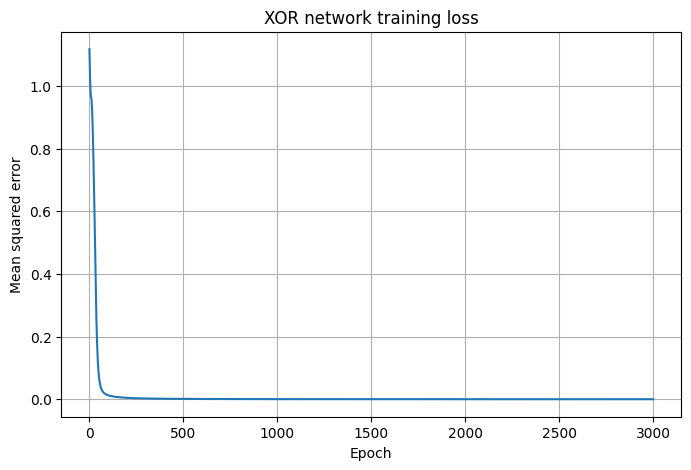

In [11]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

X_xor = np.array([
    [-1, -1],
    [-1,  1],
    [ 1, -1],
    [ 1,  1]
], dtype=np.float32)

# Bipolar XOR: equal inputs -> -1; different inputs -> +1
y_xor = np.array([[-1], [1], [1], [-1]], dtype=np.float32)

tf.keras.backend.clear_session()
tf.random.set_seed(7)

xor_model = keras.Sequential([
    layers.Input(shape=(2,)),
    layers.Dense(
        2, activation="tanh",
        kernel_initializer=keras.initializers.RandomNormal(stddev=0.7, seed=7),
        bias_initializer="zeros"
    ),
    layers.Dense(
        1, activation="tanh",
        kernel_initializer=keras.initializers.RandomNormal(stddev=0.7, seed=11),
        bias_initializer="zeros"
    )
])

xor_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.03),
    loss="mean_squared_error"
)

xor_history = xor_model.fit(
    X_xor, y_xor,
    epochs=3000,
    batch_size=4,
    verbose=0,
    shuffle=False
)

xor_outputs = xor_model.predict(X_xor, verbose=0).ravel()
xor_predictions = np.where(xor_outputs >= 0, 1, -1)

print("Architecture: 2 input units -> 2 tanh hidden units -> 1 tanh output")
print("Update method: backpropagation with Adam")
print("\nInput | Target | Output | Prediction")
for xi, target, output, pred in zip(X_xor, y_xor.ravel(), xor_outputs, xor_predictions):
    print(f"{xi} | {target:>5.0f} | {output:>7.3f} | {pred:>10.0f}")

print("\nExact classification accuracy:",
      np.mean(xor_predictions == y_xor.ravel()))

plt.figure(figsize=(8, 5))
plt.plot(xor_history.history["loss"])
plt.xlabel("Epoch")
plt.ylabel("Mean squared error")
plt.title("XOR network training loss")
plt.grid(True)
plt.show()


### Task 2 — Discussion

- Adaline updates its weights using the difference between target and linear net output.
- The bipolar AND gate is linearly separable and can be represented by one linear unit.
- XOR is not linearly separable, so a single Adaline cannot represent it.
- The XOR model adds a hidden layer with two nonlinear units. It is a small Madaline-style architecture, but not a demonstration of the original MADALINE learning rule.


# Task 3 — Associative Memories

A heteroassociative memory maps input patterns to different output patterns. An autoassociative memory stores patterns and attempts to reconstruct the original pattern from a noisy or incomplete query.


## Cell 12 — Heteroassociative memory with three pattern pairs

In [12]:
# Bipolar patterns: values must be -1 or +1
X_hetero = np.array([
    [ 1, -1,  1],
    [-1,  1,  1],
    [ 1,  1, -1]
], dtype=float)

Y_hetero = np.array([
    [ 1,  1],
    [-1,  1],
    [-1, -1]
], dtype=float)

# Correlation-based mapping matrix
W_hetero = X_hetero.T @ Y_hetero / X_hetero.shape[1]

print("Heteroassociative weight matrix (input x output):")
print(W_hetero)

rows = []
for x, target in zip(X_hetero, Y_hetero):
    raw = x @ W_hetero
    recalled = np.where(raw >= 0, 1, -1)
    rows.append({
        "Input": x.tolist(),
        "Target output": target.tolist(),
        "Raw output": np.round(raw, 3).tolist(),
        "Recalled output": recalled.tolist(),
        "Exact match": bool(np.array_equal(recalled, target))
    })

display(pd.DataFrame(rows))


Heteroassociative weight matrix (input x output):
[[ 0.33333333 -0.33333333]
 [-1.         -0.33333333]
 [ 0.33333333  1.        ]]


,Input,Target output,Raw output,Recalled output,Exact match
0,"[1.0, -1.0, 1.0]","[1.0, 1.0]","[1.667, 1.0]","[1, 1]",True
1,"[-1.0, 1.0, 1.0]","[-1.0, 1.0]","[-1.0, 1.0]","[-1, 1]",True
2,"[1.0, 1.0, -1.0]","[-1.0, -1.0]","[-1.0, -1.667]","[-1, -1]",True


## Cell 13 — Autoassociative memory and noisy recall

In [13]:
patterns = np.array([
    [ 1,  1, -1, -1,  1],
    [-1,  1, -1,  1, -1],
    [ 1, -1,  1, -1, -1]
], dtype=float)

# Hebbian autoassociative matrix, with zero diagonal
W_auto = patterns.T @ patterns
np.fill_diagonal(W_auto, 0)

def auto_recall(query, W):
    net = W @ query
    # Preserve the query bit when net input is exactly zero
    return np.where(net > 0, 1, np.where(net < 0, -1, query))

queries = []
for i, stored in enumerate(patterns):
    clean = stored.copy()
    noisy = stored.copy()
    flip_index = i % len(stored)
    noisy[flip_index] *= -1

    clean_recalled = auto_recall(clean, W_auto)
    noisy_recalled = auto_recall(noisy, W_auto)

    queries.append({
        "Stored pattern": stored.tolist(),
        "Query": clean.tolist(),
        "Noise": "None",
        "Recalled": clean_recalled.tolist(),
        "Exact match": bool(np.array_equal(clean_recalled, stored))
    })
    queries.append({
        "Stored pattern": stored.tolist(),
        "Query": noisy.tolist(),
        "Noise": f"Bit {flip_index} flipped",
        "Recalled": noisy_recalled.tolist(),
        "Exact match": bool(np.array_equal(noisy_recalled, stored))
    })

print("Autoassociative weight matrix:")
print(W_auto)
display(pd.DataFrame(queries))


Autoassociative weight matrix:
[[ 0. -1.  1. -3.  1.]
 [-1.  0. -3.  1.  1.]
 [ 1. -3.  0. -1. -1.]
 [-3.  1. -1.  0. -1.]
 [ 1.  1. -1. -1.  0.]]


,Stored pattern,Query,Noise,Recalled,Exact match
0,"[1.0, 1.0, -1.0, -1.0, 1.0]","[1.0, 1.0, -1.0, -1.0, 1.0]",None,"[1.0, 1.0, -1.0, -1.0, 1.0]",True
1,"[1.0, 1.0, -1.0, -1.0, 1.0]","[-1.0, 1.0, -1.0, -1.0, 1.0]",Bit 0 flipped,"[1.0, 1.0, -1.0, 1.0, 1.0]",False
2,"[-1.0, 1.0, -1.0, 1.0, -1.0]","[-1.0, 1.0, -1.0, 1.0, -1.0]",None,"[-1.0, 1.0, -1.0, 1.0, -1.0]",True
3,"[-1.0, 1.0, -1.0, 1.0, -1.0]","[-1.0, -1.0, -1.0, 1.0, -1.0]",Bit 1 flipped,"[-1.0, 1.0, 1.0, 1.0, -1.0]",False
4,"[1.0, -1.0, 1.0, -1.0, -1.0]","[1.0, -1.0, 1.0, -1.0, -1.0]",None,"[1.0, -1.0, 1.0, -1.0, -1.0]",True
5,"[1.0, -1.0, 1.0, -1.0, -1.0]","[1.0, -1.0, -1.0, -1.0, -1.0]",Bit 2 flipped,"[1.0, -1.0, 1.0, -1.0, 1.0]",False


### Task 3 — Discussion

- The heteroassociative matrix maps inputs to associated outputs through a matrix product and bipolar threshold.
- The autoassociative matrix stores the patterns using a Hebbian outer-product sum, with self-connections removed.
- Recall is not guaranteed to be perfect: patterns may interfere with one another, especially when they are correlated or too numerous.
- The table reports actual recall outcomes for the specified clean and one-bit-corrupted queries.


# Task 4 — Hopfield Network

The Hopfield network stores bipolar patterns in a symmetric recurrent weight matrix. The diagonal is set to zero. Neurons update asynchronously, one at a time. We track the network energy after each update.


## Cell 14 — Store patterns using the Hebbian rule

In [14]:
hop_patterns = np.array([
    [ 1, -1,  1, -1,  1, -1],
    [-1, -1,  1,  1, -1,  1],
    [ 1,  1, -1, -1,  1, -1]
], dtype=int)

n_neurons = hop_patterns.shape[1]
W_hop = hop_patterns.T @ hop_patterns / n_neurons
np.fill_diagonal(W_hop, 0)

# Symmetry check
print("Weight matrix:")
print(W_hop)
print("Symmetric:", np.allclose(W_hop, W_hop.T))
print("Diagonal is zero:", np.allclose(np.diag(W_hop), 0))


Weight matrix:
[[ 0.          0.16666667 -0.16666667 -0.5         0.5        -0.5       ]
 [ 0.16666667  0.         -0.5        -0.16666667  0.16666667 -0.16666667]
 [-0.16666667 -0.5         0.          0.16666667 -0.16666667  0.16666667]
 [-0.5        -0.16666667  0.16666667  0.         -0.5         0.5       ]
 [ 0.5         0.16666667 -0.16666667 -0.5         0.         -0.5       ]
 [-0.5        -0.16666667  0.16666667  0.5        -0.5         0.        ]]
Symmetric: True
Diagonal is zero: True


## Cell 15 — Define energy and asynchronous recall

In [15]:
def hopfield_energy(state, W):
    state = np.asarray(state, dtype=float)
    return -0.5 * state @ W @ state

def hopfield_recall(query, W, max_sweeps=30, seed=42):
    state = np.asarray(query, dtype=int).copy()
    energies = [hopfield_energy(state, W)]
    rng = np.random.default_rng(seed)

    for _ in range(max_sweeps):
        changed = False
        for i in rng.permutation(len(state)):
            net = W[i] @ state
            if net > 0:
                new_value = 1
            elif net < 0:
                new_value = -1
            else:
                new_value = state[i]  # tie: preserve current state

            if new_value != state[i]:
                state[i] = new_value
                changed = True

            energies.append(hopfield_energy(state, W))

        if not changed:
            break

    return state, np.asarray(energies)

print("Recall and energy functions defined.")


Recall and energy functions defined.


## Cell 16 — Test clean and corrupted patterns

In [16]:
hop_results = []
energy_histories = {}

for p_index, stored in enumerate(hop_patterns):
    clean_recalled, clean_energy = hopfield_recall(
        stored, W_hop, seed=100 + p_index
    )
    hop_results.append({
        "Stored pattern": stored.tolist(),
        "Query": stored.tolist(),
        "Noise": "None",
        "Recalled": clean_recalled.tolist(),
        "Exact match": bool(np.array_equal(clean_recalled, stored))
    })
    energy_histories[f"Pattern {p_index + 1} (clean)"] = clean_energy

    noisy = stored.copy()
    # Flip two bits to test recovery from corruption
    noisy[p_index % n_neurons] *= -1
    noisy[(p_index + 2) % n_neurons] *= -1

    recalled, energies = hopfield_recall(
        noisy, W_hop, seed=200 + p_index
    )
    hop_results.append({
        "Stored pattern": stored.tolist(),
        "Query": noisy.tolist(),
        "Noise": "Two bits flipped",
        "Recalled": recalled.tolist(),
        "Exact match": bool(np.array_equal(recalled, stored))
    })
    energy_histories[f"Pattern {p_index + 1} (noisy)"] = energies

results_df = pd.DataFrame(hop_results)
display(results_df)

noisy_df = results_df[results_df["Noise"] != "None"]
success_rate = noisy_df["Exact match"].mean()
print(f"Noisy recall success rate: {success_rate:.1%}")


,Stored pattern,Query,Noise,Recalled,Exact match
0,"[1, -1, 1, -1, 1, -1]","[1, -1, 1, -1, 1, -1]",None,"[1, 1, -1, -1, 1, -1]",False
1,"[1, -1, 1, -1, 1, -1]","[-1, -1, -1, -1, 1, -1]",Two bits flipped,"[1, 1, -1, -1, 1, -1]",False
2,"[-1, -1, 1, 1, -1, 1]","[-1, -1, 1, 1, -1, 1]",None,"[-1, -1, 1, 1, -1, 1]",True
3,"[-1, -1, 1, 1, -1, 1]","[-1, 1, 1, -1, -1, 1]",Two bits flipped,"[-1, -1, 1, 1, -1, 1]",True
4,"[1, 1, -1, -1, 1, -1]","[1, 1, -1, -1, 1, -1]",None,"[1, 1, -1, -1, 1, -1]",True
5,"[1, 1, -1, -1, 1, -1]","[1, 1, 1, -1, -1, -1]",Two bits flipped,"[1, 1, -1, -1, 1, -1]",True


Noisy recall success rate: 66.7%


## Cell 17 — Plot energy during recall

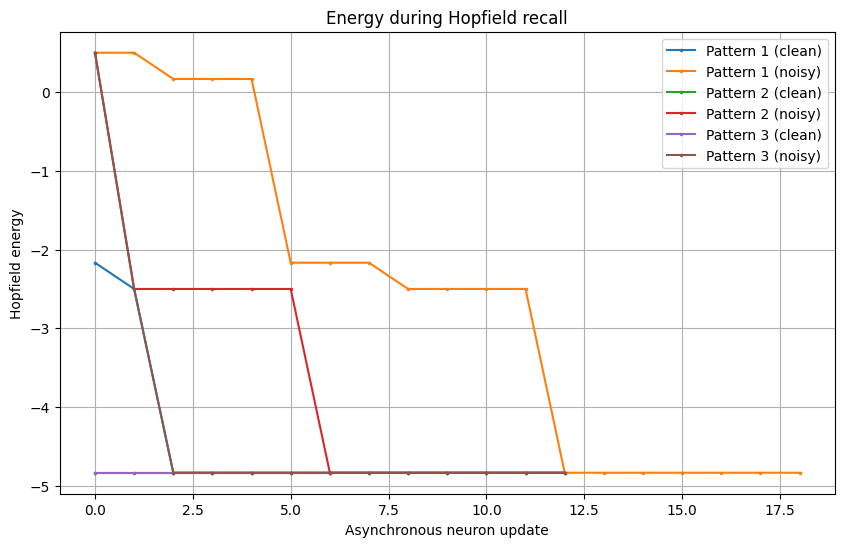

Energy should remain constant or decrease during asynchronous updates
when the weight matrix is symmetric, has a zero diagonal, and updates
follow the sign of the local field. Tie updates preserve the current state.


In [17]:
plt.figure(figsize=(10, 6))
for name, energies in energy_histories.items():
    plt.plot(range(len(energies)), energies, marker=".", markersize=3, label=name)

plt.xlabel("Asynchronous neuron update")
plt.ylabel("Hopfield energy")
plt.title("Energy during Hopfield recall")
plt.legend()
plt.grid(True)
plt.show()

print("Energy should remain constant or decrease during asynchronous updates")
print("when the weight matrix is symmetric, has a zero diagonal, and updates")
print("follow the sign of the local field. Tie updates preserve the current state.")


### Task 4 — Discussion

- Hebbian learning constructs a symmetric matrix from the stored bipolar patterns.
- Zero diagonal entries prevent self-feedback.
- Asynchronous updates use one neuron's local field at a time.
- With the standard Hopfield energy definition, valid asynchronous updates should not increase energy; zero-field ties preserve the current bit.
- A Hopfield network may recall an incorrect stable state or a spurious state. Successful recovery depends on the stored patterns, the degree of corruption, and network capacity.
- Report the noisy recall success rate shown by the notebook rather than assuming all patterns are recovered.
